In [101]:
reset

Once deleted, variables cannot be recovered. Proceed (y/[n])? y


# Description

This notebook contains the code used in the study *“Commanding the Foul Shot: A New Ensemble of Free Throw Metrics,”* with code, preprocessing details, and metric-computation routines made available where licensing permits.

All identifiable information has been removed. The notebook retains documentation of the data-processing and preparation procedures, along with the methods used to calculate the Command Metric.

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [103]:
plt.rcParams['font.size'] = 20

## Grab data here

In [109]:
print(f"df_name_id rows: {len(df_name_id)}")
print(f"df_metrics_id rows: {len(df_metrics_id)}")
print(f"merged rows: {len(df)}")

df_name_id rows: 139451
df_metrics_id rows: 101679
merged rows: 101679


In [111]:
df['release_v_mag'] = df['release_v_mag'] * 3600/5280

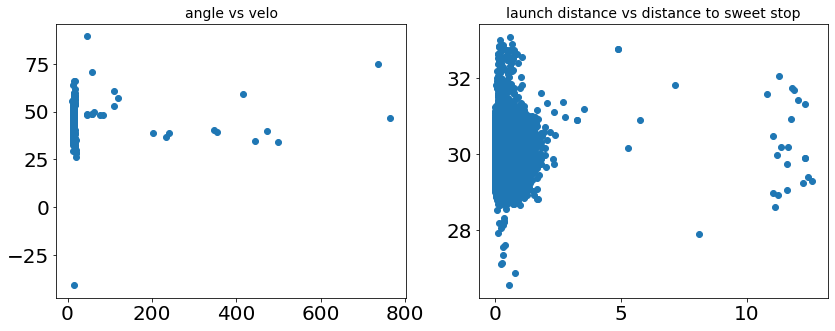

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()

In [113]:
mean = df["dist_from_sweet"].mean(skipna=True)
stdev = df["dist_from_sweet"].std(skipna=True)

k = 4     # keep values within ±4 sigma of the mean
mask = (df["dist_from_sweet"] >= mean - k*stdev) & (df["dist_from_sweet"] <= mean + k*stdev)
df = df[mask].copy()

In [114]:
mean = df["distance"].mean(skipna=True)
stdev = df["distance"].std(skipna=True)

mask = (df["distance"] >= mean - k*stdev) & (df["distance"] <= mean + k*stdev)
df = df[mask].copy()

In [115]:
mean = df["release_v_mag"].mean(skipna=True)
stdev = df["release_v_mag"].std(skipna=True)

mask = (df["release_v_mag"] >= mean - k*stdev) & (df["release_v_mag"] <= mean + k*stdev)
df = df[mask].copy()

In [116]:
mean = df["launch_angle"].mean(skipna=True)
stdev = df["launch_angle"].std(skipna=True)

mask = (df["launch_angle"] >= mean - k*stdev) & (df["launch_angle"] <= mean + k*stdev)
df = df[mask].copy()

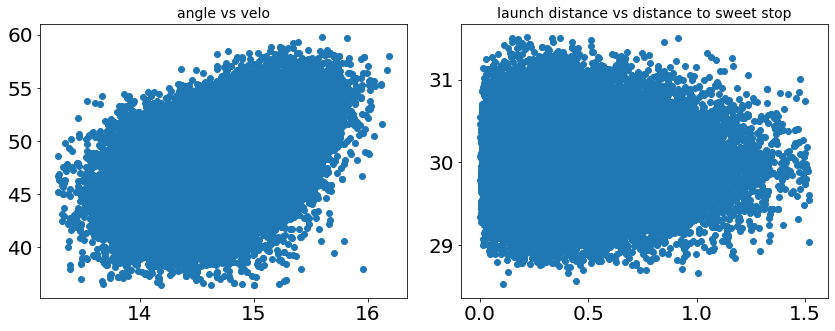

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()


In [118]:
print(f"merged rows: {len(df)}")

merged rows: 101390


total rows after excluding data points which were mis-reads... next, get player-of-interest id

In [119]:
player_id = ____
df = df[df['personid'] == player_id].copy()

In [120]:
print(f"merged rows: {len(df)}")

merged rows: 1377


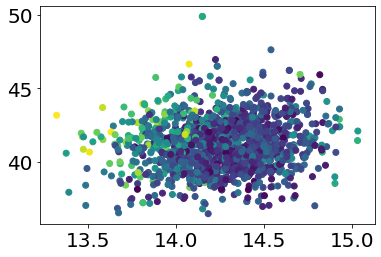

In [121]:
plt.scatter(df['release_v_mag'], df['launch_angle'], c = df['dist_from_sweet'])
plt.show()

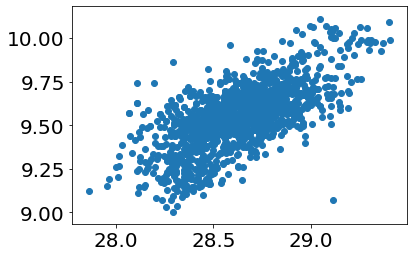

In [122]:
plt.scatter(df['x0'], df['z0'])
plt.show()

In [123]:
mean_shot_velo = np.mean( df['release_v_mag'] )
mean_shot_angle = np.mean( df['launch_angle'] )

In [124]:
mean_shot_x = np.mean( df['x0'] )
mean_shot_z = np.mean( df['z0'] )

## first, let's characterize the player of interest

In [125]:
mu = np.mean( df['dist_from_sweet'] )
sigma = np.std( df['dist_from_sweet'] )
command = 1 / (1 + np.sqrt(mu**2 + sigma**2)) # command definition and calculation for a single player... repeat for all players to get command for each player (removed to protect data)

In [126]:
shooting_percentage = (df['shotresult'] == "Made").mean()

In [127]:
print(command)

0.6588084127501663


In [128]:
print(shooting_percentage)

0.6521423384168482


# build the model

In [133]:
def shot_model(x0, z0, angle_deg, velocity_miles_hour, dist_to_bulls = None, target_z=10, g=32.174, plot=False, ax=None, label=None):
    """
    Returns the x position where projectile hits a specific z height on the way down,
    and plots the trajectory only up to that point.

    Parameters:
    - x0, z0: initial x and z coordinates (in feet)
    - angle_deg: launch angle in degrees (0° = horizontal)
    - velocity_ft_s: launch velocity in miles/hour
    - target_z: target z height to detect (default 10 ft)
    - g: gravity in ft/s²
    - plot: whether to show the trajectory plot

    Returns:
    - x_hit: x position (in feet) where projectile hits z = target_z on the way down
    """
    r_ball = 29.5 / (2*np.pi) / 12.0
    
    bullseye_x, bullseye_z = 6-11/12, 10
    x0 = 47-x0
    
    velocity_ft_s = 5280/3600 * velocity_miles_hour
    angle_rad = np.radians(-angle_deg)
    vx = -velocity_ft_s * np.cos(angle_rad)
    vz = -velocity_ft_s * np.sin(angle_rad)

    # Solve for time when z(t) = target_z
    a = -0.5 * g
    b = vz
    c = z0 - target_z

    discriminant = b**2 - 4 * a * c
    if discriminant < 0:
        return None

    t1 = (-b - np.sqrt(discriminant)) / (2 * a)
    t2 = (-b + np.sqrt(discriminant)) / (2 * a)
    t_hit = max(t1, t2)  # the time on the way down

    x_hit = x0 + vx * t_hit
    
    t = np.linspace(0, t_hit, 300)
    x = x0 + vx * t
    z = z0 + vz * t + a * t**2
    
    dist_to_bullseye = np.sqrt( (bullseye_x - x_hit)**2 )
    
    hit_rim = False
    for xi, zi in zip(x, z):
        if abs(xi - 6) > abs(xi - 4.5):
            rim_x = 4.5
        else:
            rim_x = 6
        rim_z = 10.0

        dx = xi - rim_x
        dz = zi - rim_z
        dist = np.sqrt(dx**2 + dz**2)

        if dist <= r_ball:
            hit_rim = True
            break
    
    if plot:
        plt.figure(figsize=(12, 6))
        
        plt.plot(x, z, label='Trajectory')
        plt.scatter(x_hit, target_z, c='r', s=100, label='Enters Rim')
        
        plt.plot([4.5, 6], [10, 10], c='k', label='Rim Height (10 ft)')
        plt.plot([19, 19], [0, 10], 'k--', label='Foul line (19 ft)')
        plt.scatter(bullseye_x, bullseye_z, c='g')
        
        '''
        if dist_to_bulls is not None:
            if x_hit > bullseye_x:
                plt.scatter(bullseye_x+dist_to_bulls, bullseye_z, c='k')
            else:
                plt.scatter(bullseye_x-dist_to_bulls, bullseye_z, c='k')
        '''
        plt.xlim([0,20])
        plt.ylim([0,15])#0,15
        
        plt.text(3,5,f'Missed bullseye by {abs(round(bullseye_x - x_hit,2))} ft',fontsize=14)
        
        plt.xlabel('x (ft)')
        plt.ylabel('z (ft)')
        plt.title('Foul shot side view')
        plt.legend(fontsize=14)
        plt.show()
        
        
    return [x_hit, dist_to_bullseye, hit_rim, x, z]

### Define `thetas` and `velos` as ranges of launch angles and velocities derived from player data. The underlying definitions have been omitted to protect data confidentiality.

In [159]:
# assume len(thetas) = N_t, len(velos) = N_v
N_t, N_v = len(thetas), len(velos)

# fill classification matrix
M = np.zeros((N_t, N_v))
for ti, i in enumerate(thetas):
    for vj, j in enumerate(velos):
        x_hit, dist_to_bullseye, hit_rim, xf, zf = shot_model(launch_x, launch_z, i, j)
        
        if hit_rim:
            M[ti, vj] = 1
        elif 4.5 < x_hit < 6:
            M[ti, vj] = 2
        else:
            M[ti, vj] = 0

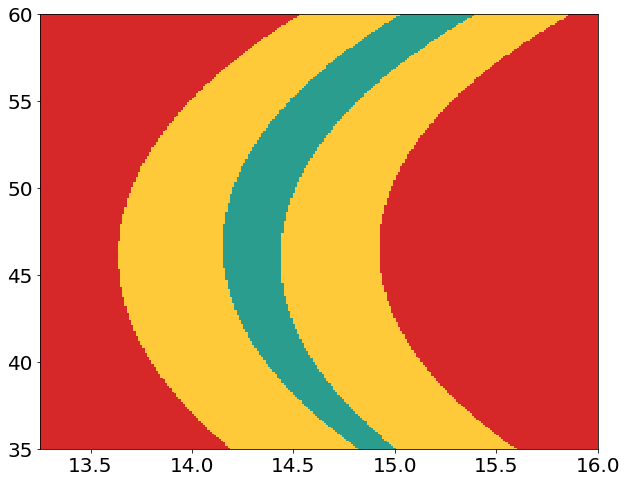

In [160]:
# plot with colormap
cmap = plt.matplotlib.colors.ListedColormap(["#d62828", "#ffca3a", "#2a9d8f"])
plt.figure(figsize=(10,8))
plt.pcolormesh(velos, thetas, M, cmap=cmap, shading="auto")
plt.show()

In [162]:
delta = 1/12 #get made/missed shots launched within a reasonable distance from the model calculated above

# For makes
mask = ((makes_filtered["x0"] - launch_x)**2 + (makes_filtered["z0"] - launch_z)**2)**0.5 <= delta
make_delta = makes_filtered[mask]

# For misses
mask = ((misses_filtered["x0"] - launch_x)**2 + (misses_filtered["z0"] - launch_z)**2)**0.5 <= delta
miss_delta = misses_filtered[mask]

In [163]:
shots_total = len(make_delta) + len(miss_delta)
print(shots_total)

153


In [164]:
len(make_delta) / (len(make_delta) + len(miss_delta))

0.6797385620915033

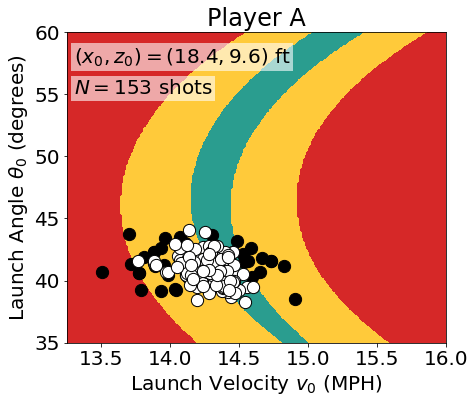

In [166]:
# plot with colormap
plt.figure(figsize=(7,6))
plt.imshow(
    M,
    origin="lower",
    extent=[min(velos), max(velos), min(thetas), max(thetas)],
    aspect="auto",
    cmap=cmap,
    interpolation="bicubic"   # or "bilinear"
)

scat2 = plt.scatter(miss_delta['release_v_mag'], miss_delta['launch_angle'], s=150, c='black', edgecolor='k', label="Misses",zorder=10)
scat1 = plt.scatter(make_delta['release_v_mag'], make_delta['launch_angle'], s=150, c='white', edgecolor='k', label="Makes",zorder=10)

plt.xlabel(r'Launch Velocity $v_0$ (MPH)')
plt.ylabel(r'Launch Angle $\theta_0$ (degrees)')

plt.text(13.3,57.5,fr'$(x_0, z_0) = ({47-launch_x:.1f}, {launch_z:.1f})$ ft',
            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=3))
plt.text(13.3,55,fr'$N = {shots_total}$ shots',
            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=3))
plt.title('Player A')

#plt.legend(loc='upper right')
plt.xticks([13.5,14.0,14.5,15,15.5,16.0])
plt.yticks([35,40,45,50,55,60])
plt.tight_layout()
#plt.savefig('command_fig8_a.png',dpi=600,pad_inches=0)

plt.show()

## given that a shot has error, how much spread can we expect in the shot

In [168]:
angle_error = np.std( df['launch_angle'] )
velocity_error = np.std( df['release_v_mag'] )

In [171]:
error_spread_matrix = np.zeros((len(thetas), len(velos)))

for i, angle in enumerate(thetas):
    for j, v in enumerate(velos):
        x_hits = []
        for d_v in [-1*velocity_error, velocity_error]:
            for d_a in [-1*angle_error, angle_error]:
                v_err = v + d_v
                a_err = angle + d_a
                x_hit, dist_to_bullseye, hit_rim, xf, zf = shot_model(launch_x, launch_z, a_err, v_err)
                if x_hit is not None:
                    x_hits.append(x_hit)

        if len(x_hits) == 4:
            error_spread_matrix[i, j] = max(x_hits) - min(x_hits)
        else:
            error_spread_matrix[i, j] = np.nan

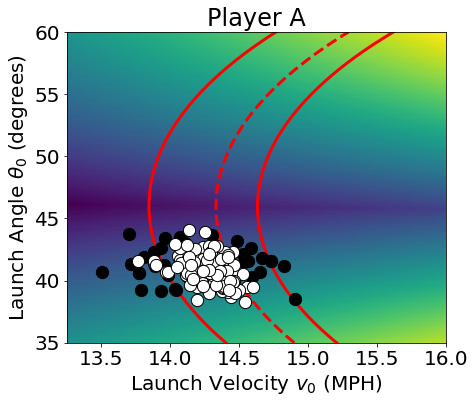

In [177]:
plt.figure(figsize=(7, 6))
plt.imshow(error_spread_matrix, 
           extent=[min(velos), max(velos), min(thetas), max(thetas)],
           origin='lower', aspect='auto')

plt.plot(v_sorted, theta_sorted, 'r--', label='Bullseye', linewidth=3)
plt.plot(frontrim_v_sorted, frontrim_theta_sorted, 'r', label='Rim', linewidth=3)
plt.plot(backrim_v_sorted, backrim_theta_sorted, 'r', linewidth=3)

plt.scatter(miss_delta['release_v_mag'], miss_delta['launch_angle'], s=150, c='black', edgecolor='k', label="Misses", zorder=10)
plt.scatter(make_delta['release_v_mag'], make_delta['launch_angle'], s=150, c='white', edgecolor='k', label="Makes", zorder=10)

plt.xlabel(r'Launch Velocity $v_0$ (MPH)')
plt.ylabel(r'Launch Angle $\theta_0$ (degrees)')
plt.title(r'Player A')
#plt.legend(loc="upper left", fontsize=16)

plt.yticks([35, 40, 45, 50, 55, 60])
plt.xticks([13.5, 14.0, 14.5, 15, 15.5, 16])

plt.tight_layout()
#plt.savefig('command_fig9_a.png',dpi=600,pad_inches=0)

plt.show()

In [172]:
from scipy.optimize import brentq

In [173]:
# Function: for a fixed angle, find velocity that hits bullseye
def f_v(v_mph, theta_deg):
    out = shot_model(launch_x, launch_z, theta_deg, v_mph, target_z=10, plot=False)
    if out is None:
        return np.nan
    x_hit, dist_to_bullseye, hit_rim, xf, zf = out
    bullseye_x = 6 - 11/12
    return x_hit - bullseye_x

solutions = []  # list of (theta, v) pairs

# loop over angles (fixed)
theta_grid = thetas
for theta in theta_grid:
    # scan velocity to find brackets where f_v changes sign
    v_vals = np.linspace(13.25, 16.0, 250)   # adjust range for the problem
    f_vals = [f_v(v, theta) for v in v_vals]

    for k in range(len(v_vals)-1):
        v1, v2 = v_vals[k], v_vals[k+1]
        f1, f2 = f_vals[k], f_vals[k+1]

        if np.isfinite(f1) and np.isfinite(f2) and (f1*f2 <= 0):
            try:
                root_v = brentq(f_v, v1, v2, args=(theta,))
                solutions.append((theta, root_v))
            except Exception:
                pass

# sort by angle for smooth plotting
solutions_sorted = sorted(solutions, key=lambda s: s[0])
theta_sorted = [s[0] for s in solutions_sorted]
v_sorted = [s[1] for s in solutions_sorted]

In [174]:
solutions_frontrim = []  # list of (theta, v) pairs that hit the front rim

# loop over angles (fixed)
theta_grid = thetas
for theta in theta_grid:
    # scan velocity to find brackets where f_v changes sign
    v_vals = np.linspace(13.25, 16.0, 250)   # adjust range for your problem
    f_vals = [f_v(v, theta) for v in v_vals]

    for k in range(len(v_vals)-1):
        v1, v2 = v_vals[k], v_vals[k+1]
        f1, f2 = f_vals[k], f_vals[k+1]

        if np.isfinite(f1) and np.isfinite(f2) and (f1*f2 <= 0):
            try:
                root_v = brentq(f_v, v1, v2, args=(theta,))
                solutions_frontrim.append((theta, root_v))
            except Exception:
                pass

# sort by angle for smooth plotting
solutions_frontrim_sorted = sorted(solutions_frontrim, key=lambda s: s[0])
frontrim_theta_sorted = [s[0] for s in solutions_frontrim_sorted]
frontrim_v_sorted = [s[1] for s in solutions_frontrim_sorted]

In [175]:
solutions_backrim = []  # list of (theta, v) pairs the hit the back rim

# loop over angles (fixed)
theta_grid = thetas
for theta in theta_grid:
    # scan velocity to find brackets where f_v changes sign
    v_vals = np.linspace(13.25, 16.0, 250)   # adjust range for your problem
    f_vals = [f_v(v, theta) for v in v_vals]

    for k in range(len(v_vals)-1):
        v1, v2 = v_vals[k], v_vals[k+1]
        f1, f2 = f_vals[k], f_vals[k+1]

        if np.isfinite(f1) and np.isfinite(f2) and (f1*f2 <= 0):
            try:
                root_v = brentq(f_v, v1, v2, args=(theta,))
                solutions_backrim.append((theta, root_v))
            except Exception:
                pass

# sort by angle for smooth plotting
solutions_backrim_sorted = sorted(solutions_backrim, key=lambda s: s[0])
backrim_theta_sorted = [s[0] for s in solutions_backrim_sorted]
backrim_v_sorted = [s[1] for s in solutions_backrim_sorted]

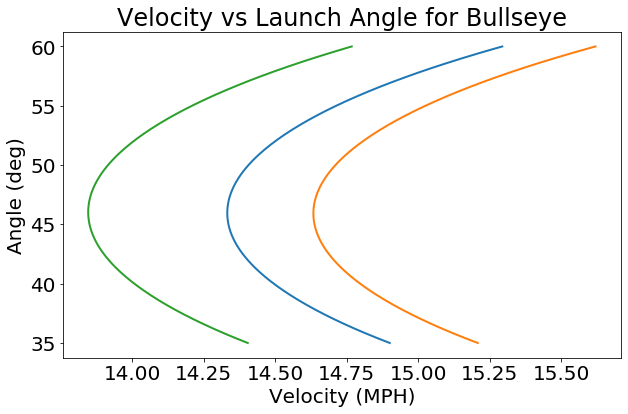

In [176]:
# Plot smooth line
plt.figure(figsize=(10,6))
plt.plot(v_sorted, theta_sorted, linewidth=2)
plt.plot(frontrim_v_sorted, frontrim_theta_sorted, linewidth=2)
plt.plot(backrim_v_sorted, backrim_theta_sorted, linewidth=2)
plt.xlabel('Velocity (MPH)')
plt.ylabel('Angle (deg)')
plt.title('Velocity vs Launch Angle for Bullseye')
plt.show()

### deviations in shot trajectories

In [70]:
bullseye_x, bullseye_z = 6-11/12, 10

In [71]:
v1, theta1 = 14.35, 46
v2, theta2 = 14.8, 36

In [72]:
x0 = np.mean( df_filtered['x0'] )
z0 = np.mean( df_filtered['z0'] )
angle_error = np.std( df_filtered['launch_angle'] )
velocity_error = np.std( df_filtered['release_v_mag'] )

In [73]:
a,b,c,x1_good,z1_good = shot_model(x0, z0, theta1, v1)
a,b,c,x1_c,z1_c = shot_model(x0, z0, theta1 + angle_error, v1 + velocity_error)
a,b,c,x1_d,z1_d = shot_model(x0, z0, theta1 - angle_error, v1 - velocity_error)
a,b,c,x1_a,z1_a = shot_model(x0, z0, theta1 - angle_error, v1 + velocity_error)
a,b,c,x1_b,z1_b = shot_model(x0, z0, theta1 + angle_error, v1 - velocity_error)

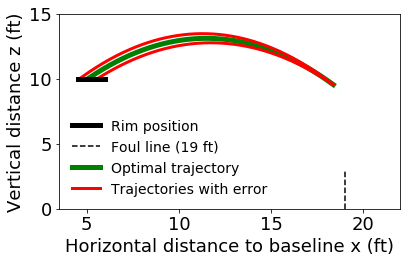

In [111]:
plt.figure(figsize=(6,4))

plt.plot([4.5, 6], [10, 10], c='k', linewidth=5, label='Rim position', zorder=10)
plt.plot([19, 19], [0, 3], 'k--', label='Foul line (19 ft)')
#plt.scatter(bullseye_x, bullseye_z, c='g')

plt.plot(x1_good, z1_good,c='g',linewidth=5, label='Optimal trajectory')

#plt.plot(x1_a, z1_a, 'r')
#plt.plot(x1_b, z1_b, 'r')
plt.plot(x1_c, z1_c, 'r',linewidth=3, label='Trajectories with error')
plt.plot(x1_d, z1_d, 'r',linewidth=3)

plt.xlim([3.5,22])
plt.ylim([0,15])

plt.yticks([0,5,10,15])

plt.xlabel('Horizontal distance to baseline x (ft)')
plt.ylabel('Vertical distance z (ft)')
plt.legend(loc="lower left", frameon=False, fontsize=14)

plt.tight_layout()
#plt.savefig('minimal_spread_shot.png',dpi=600,pad_inches=0)

plt.show()

In [112]:
a,b,c,x2_good,z2_good = shot_model(x0, z0, theta2, v2)
a,b,c,x2_c,z2_c = shot_model(x0, z0, theta2 + angle_error, v2 + velocity_error)
a,b,c,x2_d,z2_d = shot_model(x0, z0, theta2 - angle_error, v2 - velocity_error)
a,b,c,x2_a,z2_a = shot_model(x0, z0, theta2 - angle_error, v2 + velocity_error)
a,b,c,x2_b,z2_b = shot_model(x0, z0, theta2 + angle_error, v2 - velocity_error)

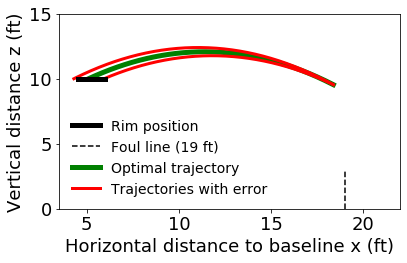

In [114]:
plt.figure(figsize=(6,4))

plt.plot([4.5, 6], [10, 10], c='k', linewidth=5, label='Rim position', zorder=10)
plt.plot([19, 19], [0, 3], 'k--', label='Foul line (19 ft)')
#plt.scatter(bullseye_x, bullseye_z, c='g')

plt.plot(x2_good, z2_good,c='g',linewidth=5, label='Optimal trajectory')

#plt.plot(x1_a, z1_a, 'r')
#plt.plot(x1_b, z1_b, 'r')
plt.plot(x2_c, z2_c, 'r',linewidth=3, label='Trajectories with error')
plt.plot(x2_d, z2_d, 'r',linewidth=3)

plt.xlim([3.5,22])
plt.ylim([0,15])

plt.yticks([0,5,10,15])

plt.xlabel('Horizontal distance to baseline x (ft)')
plt.ylabel('Vertical distance z (ft)')
plt.legend(loc="lower left", frameon=False, fontsize=14)

plt.tight_layout()
#plt.savefig('maximal_spread_shot.png',dpi=600,pad_inches=0)

plt.show()

## shot model correction based on gradient descent

In [121]:
def xf(theta, v0, x0, z0, zf=10, g=32.174):
    """Final horizontal position given angle, speed, and positions. All units in ft and rads."""
    under_sqrt = v0**2*np.sin(theta)**2 - 2*g*(zf - z0)
    if under_sqrt < 0:
        return np.nan  # infeasible trajectory
    D = np.sqrt(under_sqrt)
    return x0 - (v0*np.cos(theta)) * (v0*np.sin(theta) + D) / g

def partials(theta, v0, x0, z0, zf=10, g=32.174):
    """Analytic partial derivatives of xf wrt theta and v0. All units in ft and rads."""
    D = np.sqrt(v0**2 * np.sin(theta)**2 - 2*g*(zf - z0))
    dx_dv0 = - (2*np.cos(theta)/g) * (
        v0*np.sin(theta) + (v0**2 * np.sin(theta)**2 - g*(zf-z0)) / D
    )
    dx_dtheta = (v0*np.sin(theta)/g)*(v0*np.sin(theta) + D) \
                - (v0**2 * np.cos(theta)**2 / g) * (1 + v0*np.sin(theta)/D)
    return dx_dtheta, dx_dv0

def gradient_descent(theta0, v0_0, x0, z0, zf=10, xg=5.08333,
                     g=32.174, lr=1e-4, tol=1e-4, max_iters=10000):
    """
    Gradient descent to minimize squared loss between xf and xg.
    Returns optimized (theta, v0), final error, and number of iterations.
    """
    theta, v0 = theta0 * np.pi/180, v0_0 * 5280/3600
    x0 = 47-x0

    for it in range(max_iters):
        xf_val = xf(theta, v0, x0, z0)
        if np.isnan(xf_val):  # trajectory not feasible
            return None, None, np.inf, it
        
        err = xf_val - xg
        if abs(err) < tol:
            break

        # compute gradients
        dtheta, dv0 = partials(theta, v0, x0, z0)
        grad_J_theta = err * dtheta
        grad_J_v0 = err * dv0
        
        grad = np.array([grad_J_theta, grad_J_v0])
        scale = np.array([theta, v0])
        grad /= scale
        grad /= np.linalg.norm(grad) + 1e-8
        
        # update parameters
        theta -= lr * grad[0] * scale[0]
        v0    -= lr * grad[1] * scale[1]
    
    theta, v0 = theta * 180/np.pi, v0 * 3600/5280
    return theta, v0, err, it+1

In [123]:
x0 = data[5]
z0 = data[7]
velo = data[8]
theta = data[9]
dist_to_bulls = data[10]

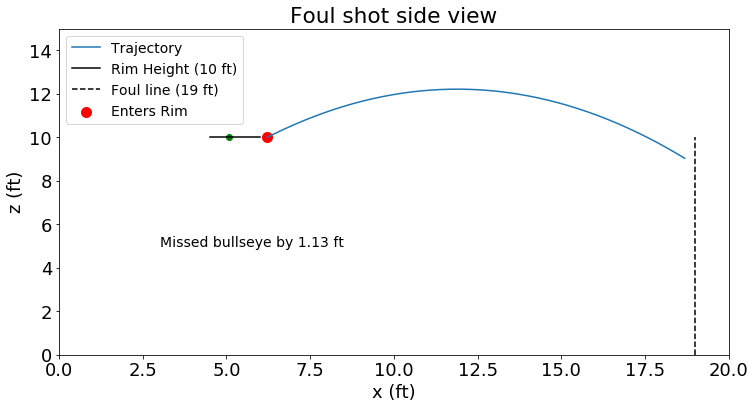

In [124]:
a,b,c,x,z = shot_model(x0, z0, theta, velo, dist_to_bulls = dist_to_bulls, plot=True)

In [125]:
theta_opt, v0_opt, final_err, iters = gradient_descent(
    theta, velo, x0, z0, lr=1e-3, tol=1e-3, max_iters=5000
)

print(f"Optimized angle (rad): {theta_opt}")
print(f"Optimized speed (m/s): {v0_opt}")
print(f"Final horizontal error: {final_err:.4f} m")
print(f"Iterations: {iters}")

Optimized angle (rad): 47.027562482590824
Optimized speed (m/s): 14.778216527473731
Final horizontal error: -0.0010 m
Iterations: 1130


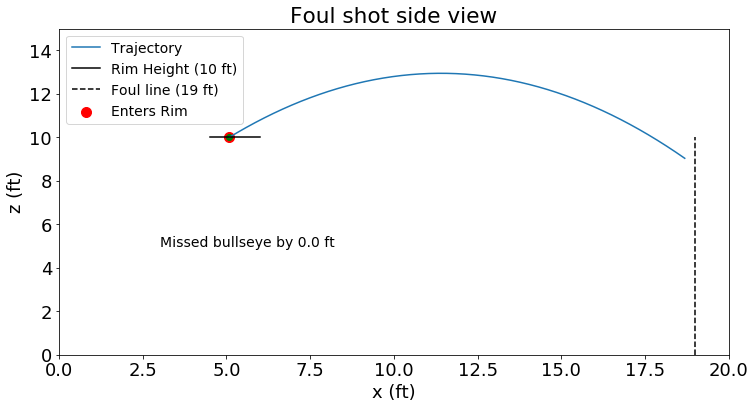

In [126]:
a,b,c,x_opt,z_opt = shot_model(x0, z0, theta_opt, v0_opt, dist_to_bulls = dist_to_bulls, plot=True)

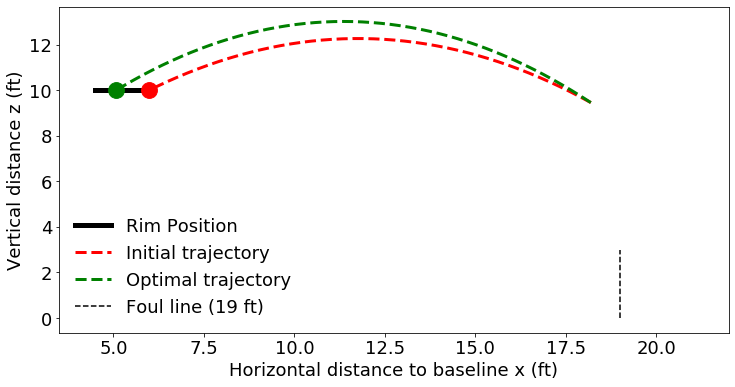

In [102]:
plt.figure(figsize=(12, 6))

plt.plot([4.5, 6], [10, 10], c='k', linewidth=5, label='Rim Position')

plt.plot(x, z, 'r--', linewidth=3, label='Initial trajectory', zorder=10)
plt.scatter(x[-1], 10, c='r', s=250, zorder=10)

plt.plot(x_opt, z_opt, 'g--', linewidth=3, label='Optimal trajectory', zorder=10)
plt.scatter(x_opt[-1], 10, c='g', s=250, zorder=10)

plt.plot([19, 19], [0, 3], 'k--', label='Foul line (19 ft)')

plt.scatter(6-11/12, 10, c='g')

plt.xlim([3.5,22])
#plt.ylim([-0.5,16])#0,15

plt.xlabel('Horizontal distance to baseline x (ft)')
plt.ylabel('Vertical distance z (ft)')
plt.legend(loc="lower left", frameon=False)
plt.show()